In [1]:
from google.colab import files
uploaded = files.upload()

Saving archive (4).zip to archive (4) (1).zip


In [2]:
import zipfile
import os

zip_path = list(uploaded.keys())[0]
extract_path = "/content/employee_segmentation_data"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        print(os.path.join(root, filename))

/content/employee_segmentation_data/WA_Fn-UseC_-HR-Employee-Attrition.csv


In [3]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
import seaborn as sns

csv_files = glob.glob(
    "/content/employee_segmentation_data/**/*.csv",
    recursive=True
)

print("CSV files found:", csv_files)

if not csv_files:
    raise FileNotFoundError(
        "No CSV found. Upload and extract the dataset first."
    )

df = pd.read_csv(csv_files[0])

print("Dataset shape:", df.shape)
display(df.head())
df.info()

CSV files found: ['/content/employee_segmentation_data/WA_Fn-UseC_-HR-Employee-Attrition.csv']
Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [4]:
# Remove columns that are constant or only identify employees
df = df.drop(
    columns=[
        "EmployeeCount",
        "EmployeeNumber",
        "Over18",
        "StandardHours"
    ],
    errors="ignore"
)

# Check attrition and department categories
display(df["Department"].value_counts())
display(df["Attrition"].value_counts())

# Check missing values and duplicates
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

,count
Department,
Research & Development,961
Sales,446
Human Resources,63


,count
Attrition,
No,1233
Yes,237


Missing values: 0
Duplicate rows: 0


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Keep outcomes for analysis, not for clustering
analysis_df = df.copy()

X = df.drop(columns=["Attrition"], errors="ignore")

numeric_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

X_scaled = preprocessor.fit_transform(X)

# Convert sparse output to a dense array if needed
if hasattr(X_scaled, "toarray"):
    X_scaled = X_scaled.toarray()

print("Prepared feature matrix:", X_scaled.shape)

Prepared feature matrix: (1470, 51)


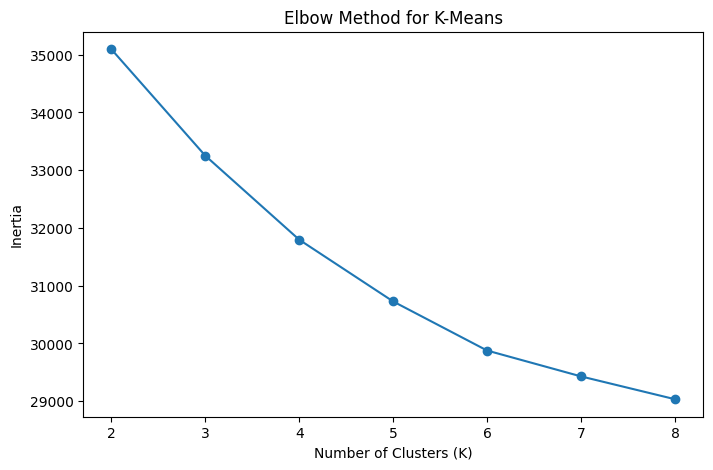

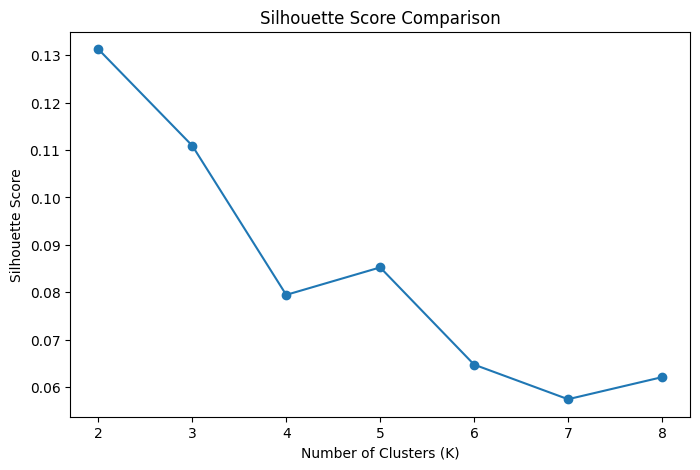

,K,Inertia,Silhouette Score
0,2,35095.0671,0.1313
1,3,33251.6631,0.1109
2,4,31796.5984,0.0795
3,5,30727.1943,0.0853
4,6,29877.2844,0.0648
5,7,29429.2941,0.0575
6,8,29034.1481,0.0621


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")
plt.show()

display(pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
}).round(4))

In [7]:
best_k = 4

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

analysis_df["KMeans_Cluster"] = kmeans.fit_predict(
    X_scaled
)

print("K-Means Silhouette Score:",
      round(silhouette_score(
          X_scaled, analysis_df["KMeans_Cluster"]
      ), 4))

display(
    analysis_df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .rename("Employee Count")
    .to_frame()
)

K-Means Silhouette Score: 0.0795


,Employee Count
KMeans_Cluster,
0,720
1,335
2,197
3,218


In [8]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hierarchical = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)

analysis_df["Hierarchical_Cluster"] = (
    hierarchical.fit_predict(X_scaled)
)

print(
    "Hierarchical Silhouette Score:",
    round(
        silhouette_score(
            X_scaled,
            analysis_df["Hierarchical_Cluster"]
        ), 4
    )
)

display(
    analysis_df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
    .rename("Employee Count")
    .to_frame()
)

Hierarchical Silhouette Score: 0.0687


,Employee Count
Hierarchical_Cluster,
0,223
1,739
2,205
3,303


Explained variance by PC1 and PC2: 0.2427


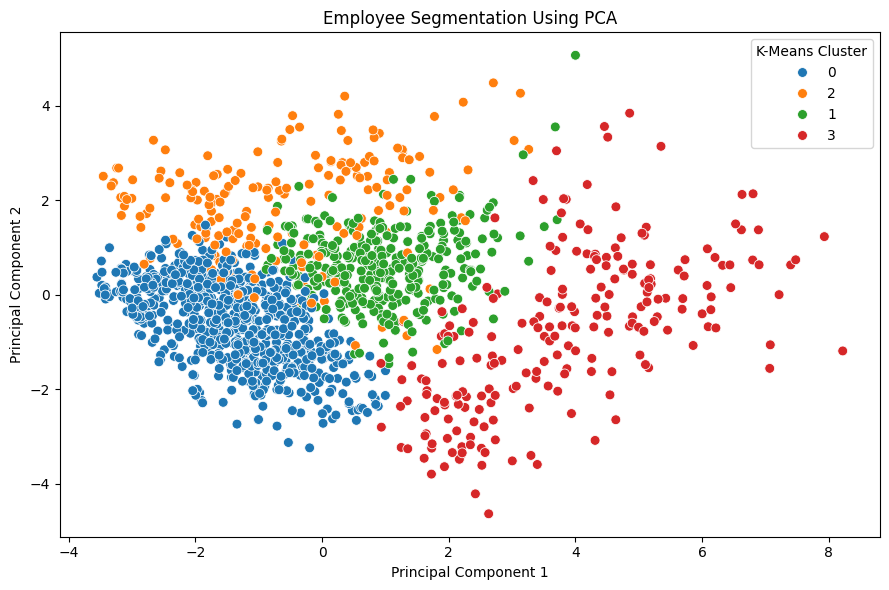

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

analysis_df["PC1"] = X_pca[:, 0]
analysis_df["PC2"] = X_pca[:, 1]

print("Explained variance by PC1 and PC2:",
      round(pca.explained_variance_ratio_.sum(), 4))

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=analysis_df["PC1"],
    y=analysis_df["PC2"],
    hue=analysis_df["KMeans_Cluster"].astype(str),
    palette="tab10",
    s=50
)

plt.title("Employee Segmentation Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="K-Means Cluster")
plt.tight_layout()
plt.show()

In [10]:
pca_summary = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Explained Variance Ratio":
        pca.explained_variance_ratio_
})

display(pca_summary.round(4))

print(
    "Total variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

,Component,Explained Variance Ratio
0,PC1,0.1744
1,PC2,0.0683


Total variance explained by two components: 24.27 %


Department,Human Resources,Research & Development,Sales
KMeans_Cluster,,,
0,34,472,214
1,9,208,118
2,7,138,52
3,13,143,62


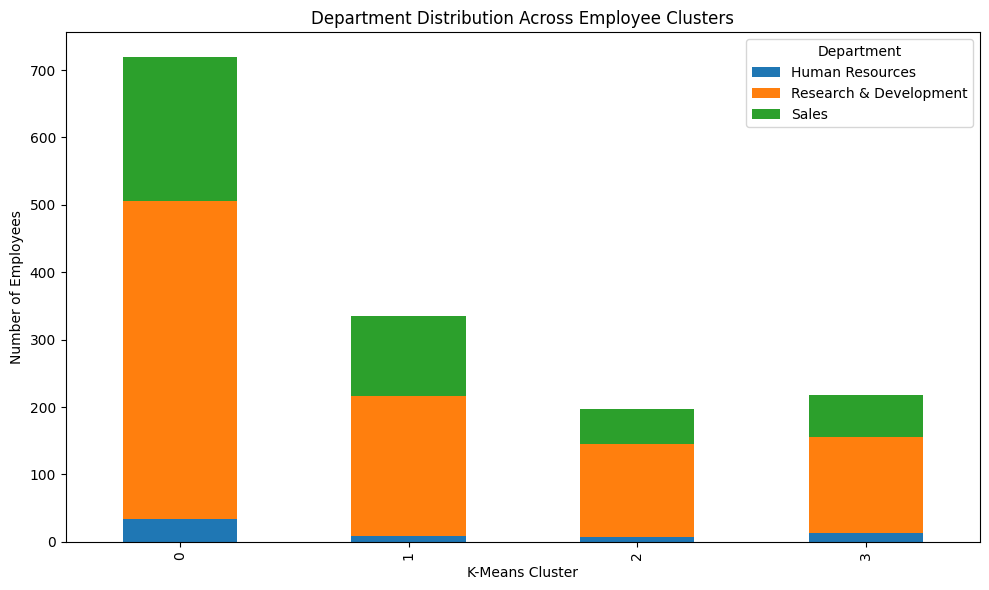

In [11]:
department_segments = pd.crosstab(
    analysis_df["KMeans_Cluster"],
    analysis_df["Department"]
)

display(department_segments)

department_segments.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Department Distribution Across Employee Clusters")
plt.xlabel("K-Means Cluster")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

In [12]:
performance_summary = analysis_df.groupby(
    "KMeans_Cluster"
).agg(
    Employee_Count=("JobLevel", "size"),
    Average_Performance=("PerformanceRating", "mean"),
    Average_Job_Satisfaction=("JobSatisfaction", "mean"),
    Average_Environment_Satisfaction=(
        "EnvironmentSatisfaction", "mean"
    ),
    Average_Years_At_Company=("YearsAtCompany", "mean"),
    Average_Monthly_Income=("MonthlyIncome", "mean")
).round(2)

display(performance_summary)

,Employee_Count,Average_Performance,Average_Job_Satisfaction,Average_Environment_Satisfaction,Average_Years_At_Company,Average_Monthly_Income
KMeans_Cluster,,,,,,
0,720,3.00,2.72,2.69,3.42,4359.00
1,335,3.01,2.80,2.82,10.35,6154.73
2,197,4.00,2.74,2.63,5.78,5047.76
3,218,3.12,2.65,2.76,14.84,15433.88


In [13]:
analysis_df["Attrition_Flag"] = (
    analysis_df["Attrition"].map({"Yes": 1, "No": 0})
)

retention_summary = analysis_df.groupby(
    "KMeans_Cluster"
).agg(
    Employee_Count=("Attrition_Flag", "size"),
    Employees_Left=("Attrition_Flag", "sum"),
    Attrition_Rate=("Attrition_Flag", "mean"),
    Average_Job_Satisfaction=("JobSatisfaction", "mean"),
    Average_Overtime=("OverTime",
                      lambda x: (x == "Yes").mean())
)

retention_summary["Attrition_Rate"] *= 100
retention_summary["Average_Overtime"] *= 100

retention_summary = retention_summary.round(2)

display(
    retention_summary.sort_values(
        "Attrition_Rate", ascending=False
    )
)

,Employee_Count,Employees_Left,Attrition_Rate,Average_Job_Satisfaction,Average_Overtime
KMeans_Cluster,,,,,
0,720,150,20.83,2.72,29.44
2,197,37,18.78,2.74,29.95
1,335,32,9.55,2.80,24.48
3,218,18,8.26,2.65,28.90


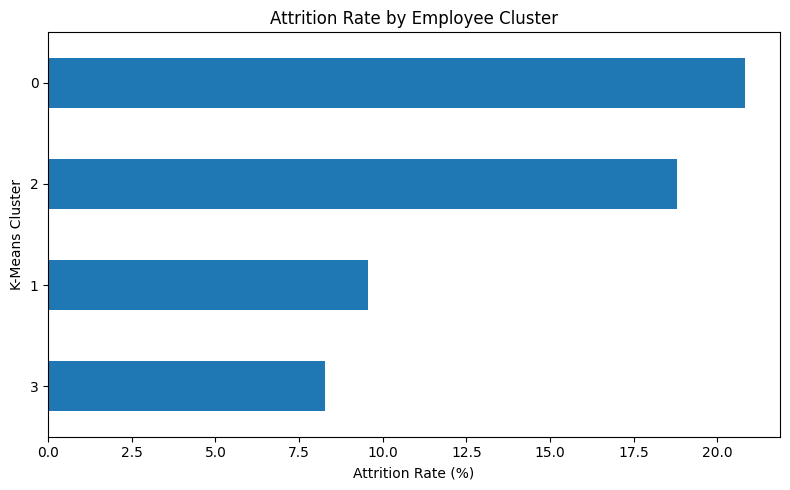

In [14]:
retention_summary.sort_values(
    "Attrition_Rate"
)["Attrition_Rate"].plot(
    kind="barh",
    figsize=(8, 5)
)

plt.xlabel("Attrition Rate (%)")
plt.ylabel("K-Means Cluster")
plt.title("Attrition Rate by Employee Cluster")
plt.tight_layout()
plt.show()

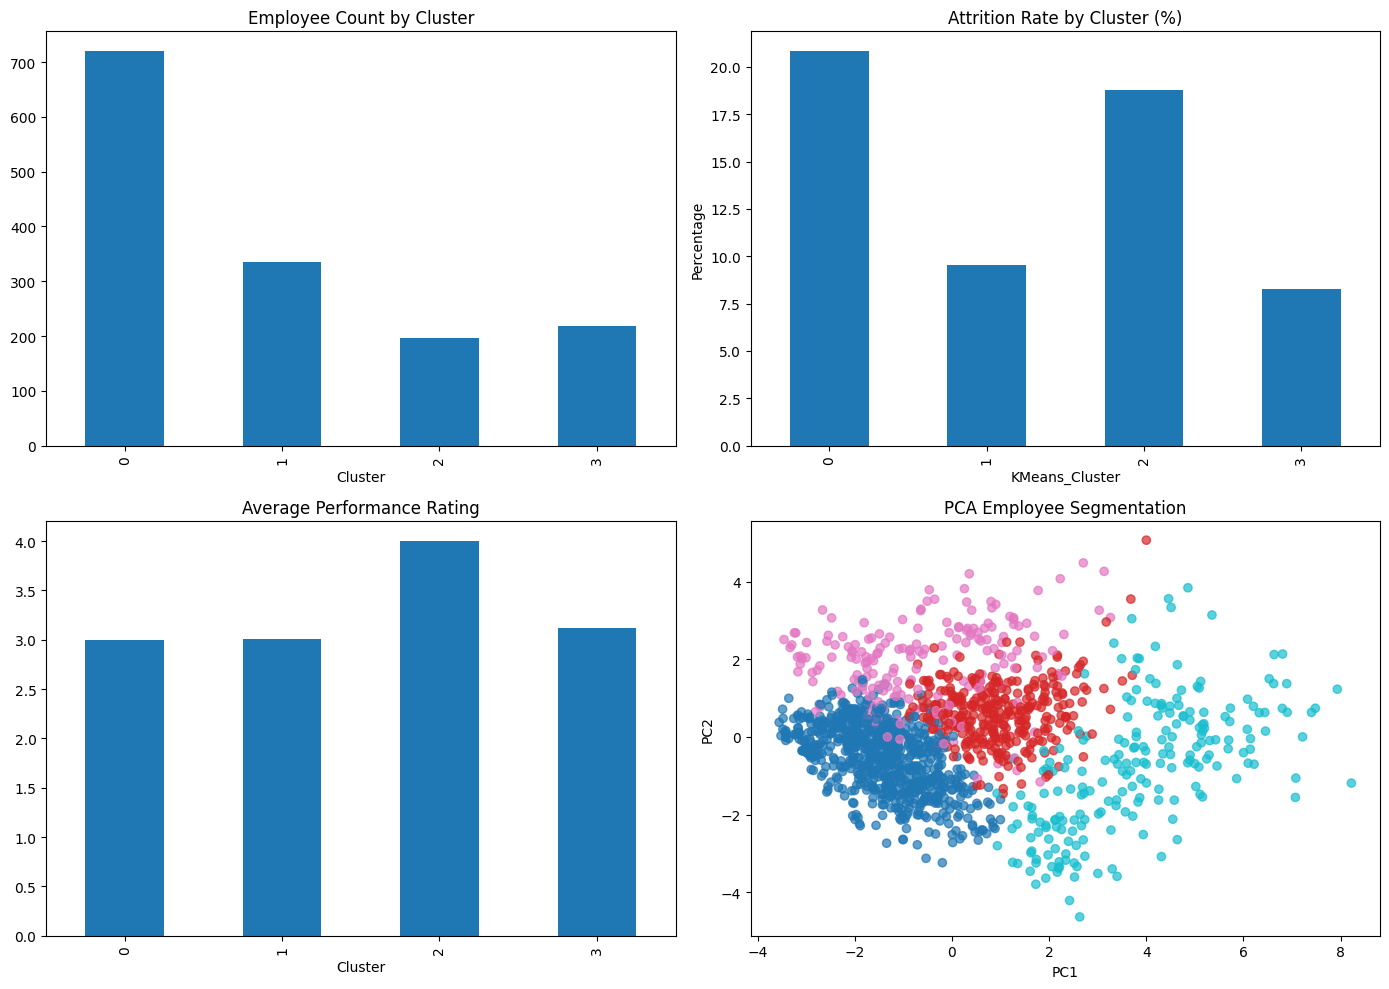

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Employee count by cluster
analysis_df["KMeans_Cluster"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0, 0]
)
axes[0, 0].set_title("Employee Count by Cluster")
axes[0, 0].set_xlabel("Cluster")

# Attrition rate by cluster
retention_summary["Attrition_Rate"].sort_index().plot(
    kind="bar", ax=axes[0, 1]
)
axes[0, 1].set_title("Attrition Rate by Cluster (%)")
axes[0, 1].set_ylabel("Percentage")

# Average performance by cluster
performance_summary["Average_Performance"].plot(
    kind="bar", ax=axes[1, 0]
)
axes[1, 0].set_title("Average Performance Rating")
axes[1, 0].set_xlabel("Cluster")

# PCA scatter plot
scatter = axes[1, 1].scatter(
    analysis_df["PC1"],
    analysis_df["PC2"],
    c=analysis_df["KMeans_Cluster"],
    cmap="tab10",
    alpha=0.7
)
axes[1, 1].set_title("PCA Employee Segmentation")
axes[1, 1].set_xlabel("PC1")
axes[1, 1].set_ylabel("PC2")

plt.tight_layout()
plt.savefig(
    "Workforce_Analytics_Dashboard.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [16]:
import os

os.makedirs("reports", exist_ok=True)

# Employee Segmentation Report data
analysis_df.to_csv(
    "reports/employee_segments.csv", index=False
)

performance_summary.to_csv(
    "reports/performance_summary.csv"
)

retention_summary.to_csv(
    "reports/retention_summary.csv"
)

department_segments.to_csv(
    "reports/department_segments.csv"
)

pca_summary.to_csv(
    "reports/pca_summary.csv", index=False
)

print("All report data files have been saved.")

All report data files have been saved.


In [17]:
from google.colab import files

files.download("Workforce_Analytics_Dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>